# ANN vs SNN on FER-2013 

Comparison of an ImageNet-pretrained **ResNet18** (`ANN_ref`), a **SEW-ResNet18 with ReLU** (`SEW_ReLU`, same topology as the SNN, no spikes) and the **SEW-ResNet18 with LIF neurons** (`SNN_LIF`).

**What changed with respect to `snn_fer.ipynb`**

| Issue in v1 | Fix in v2 |
|---|---|
| Test split used for checkpoint selection and early stopping | Stratified **validation split** carved from the training set; the test split is evaluated **once**, after training |
| Single run | **Several seeds** (`cfg.seeds`), results reported as mean ± std, McNemar test and bootstrap CI |
| ANN and SNN not comparable (pretraining, stem, loss, input scaling) | New control `SEW_ReLU` (same topology as the SNN, from scratch, same recipe); all recipe differences are listed in `MODEL_SPECS` |
| SNN `T_max=2×epochs` with only `epochs` epochs | `t_max_factor` explicit, default 1.0 for all models |
| ANN stem declared 3×3 but given 7×7 weights | Explicit `Conv2d(1, 64, 7, stride=1, padding=cfg.ann_stem_padding)` |
| Per-class report taken from the **last** epoch | Metrics computed from the **best checkpoint** reloaded from disk |
| Errors silently skipped in `try/except: continue` | Errors are raised |
| Power sampled during training only | Separate **inference** measurement: NVML energy counter, idle power subtracted, repeats, batch 1 and 64 |
| SynOps = spikes/(T·B)·fan-in divided by the number of images (off by T·B = 128) | SynOps = measured input firing rate × dense MACs, per layer, per image, over all T; dense MACs of every model counted |
| No calibration, no run metadata | ECE, environment/config/git hash saved with the results |

Run first with `cfg.quick_test = True` (a few minutes) to check the whole pipeline, then set it to `False`.

## 1. Imports and environment

In [1]:
import os, json, time, random, platform, subprocess, warnings, threading
from collections import Counter, OrderedDict, defaultdict
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from scipy.stats import binomtest

import spikingjelly
from snn_model import (create_sew_resnet18, reset_snn_state, test_sew_resnet, get_spiking_layers)
from snn_model import SpikeStatsRecorder

warnings.filterwarnings('ignore')
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')   # needed for deterministic mode
if not hasattr(np, 'int'):
    np.int = int            # compatibility shim kept from v1 (old libraries using np.int)
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def get_environment():
    """Collect versions and hardware information for reproducibility."""
    import importlib.metadata as md_
    def ver(pkg):
        try:
            return md_.version(pkg)
        except Exception:
            return 'unknown'
    try:
        git = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD'],
                                      stderr=subprocess.DEVNULL).decode().strip()
    except Exception:
        git = 'n/a'
    return {
        'date'        : datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'python'      : platform.python_version(),
        'platform'    : platform.platform(),
        'torch'       : torch.__version__,
        'torchvision' : ver('torchvision'),
        'spikingjelly': ver('spikingjelly'),
        'numpy'       : np.__version__,
        'cuda'        : torch.version.cuda,
        'gpu'         : torch.cuda.get_device_name() if torch.cuda.is_available() else 'cpu',
        'git_commit'  : git,
    }

ENV = get_environment()
for k, v in ENV.items():
    print(f"{k:<13}: {v}")

/home/dieudo/anaconda3/envs/env_snn/lib/python3.10/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


date         : 2026-11-03 21:25:11
python       : 3.10.20
platform     : Linux-7.0.0-38-generic-x86_64-with-glibc2.39
torch        : 2.11.0+cu130
torchvision  : 0.26.0
spikingjelly : 0.0.0.0.14
numpy        : 2.2.5
cuda         : 13.0
gpu          : NVIDIA GeForce RTX 3050 6GB Laptop GPU
git_commit   : ebbe2e5


## 2. Utilities (seeding, metrics, statistics)

In [2]:
def set_seed(seed, deterministic=False):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True, warn_only=True)


def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


def to_jsonable(o):
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer):  return int(o)
    if isinstance(o, np.ndarray):  return o.tolist()
    if isinstance(o, dict):        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    return o


def expected_calibration_error(probs, labels, n_bins=15):
    """ECE with equal-width confidence bins (probs: [N, C] numpy array)."""
    probs  = np.asarray(probs); labels = np.asarray(labels)
    conf   = probs.max(axis=1)
    pred   = probs.argmax(axis=1)
    correct = (pred == labels).astype(float)
    edges  = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def bootstrap_ci(correct, n_boot=2000, alpha=0.05, seed=0):
    """Percentile bootstrap CI of the accuracy from a 0/1 correctness vector."""
    correct = np.asarray(correct, dtype=float)
    rng = np.random.RandomState(seed)
    n = len(correct)
    accs = np.array([correct[rng.randint(0, n, n)].mean() for _ in range(n_boot)])
    return float(np.percentile(accs, 100 * alpha / 2)), float(np.percentile(accs, 100 * (1 - alpha / 2)))


def mcnemar_exact(correct_a, correct_b):
    """Exact McNemar test on paired correctness vectors. Returns (b, c, p-value)."""
    a = np.asarray(correct_a, dtype=bool); b_ = np.asarray(correct_b, dtype=bool)
    b = int(np.sum(a & ~b_)); c = int(np.sum(~a & b_))
    if b + c == 0:
        return b, c, 1.0
    return b, c, float(binomtest(min(b, c), b + c, 0.5).pvalue)

## 3. GPU monitoring (power, memory, energy counter)

In [3]:
try:
    import pynvml
    pynvml.nvmlInit()
    gpu_handle     = pynvml.nvmlDeviceGetHandleByIndex(0)
    gpu_monitoring = True
    _name = pynvml.nvmlDeviceGetName(gpu_handle)
    gpu_name = _name.decode('utf-8') if isinstance(_name, bytes) else _name
    print(f"GPU monitoring enabled : {gpu_name}")
except Exception as e:
    gpu_monitoring, gpu_handle, gpu_name = False, None, 'n/a'
    print(f"GPU monitoring disabled : {e}")


def get_gpu_power_usage():
    """Instantaneous whole-board power in W."""
    return pynvml.nvmlDeviceGetPowerUsage(gpu_handle) / 1000.0 if gpu_monitoring else 0.0


def get_gpu_memory_usage():
    """Device memory in use (all processes) in GB."""
    return pynvml.nvmlDeviceGetMemoryInfo(gpu_handle).used / 1024**3 if gpu_monitoring else 0.0


def get_gpu_energy_counter_mJ():
    """Cumulative energy counter in mJ, or None if unsupported."""
    if not gpu_monitoring:
        return None
    try:
        return pynvml.nvmlDeviceGetTotalEnergyConsumption(gpu_handle)
    except Exception:
        return None


ENERGY_COUNTER_OK = get_gpu_energy_counter_mJ() is not None
print(f"NVML energy counter available : {ENERGY_COUNTER_OK}")


class GPUEnergyMeter:
    """
    Context manager measuring the GPU energy spent in a block.
    Uses the hardware energy counter when available, otherwise integrates
    power samples taken at `sample_hz` in a background thread.
    Attributes after exit: energy_J, duration_s, avg_power_W.
    """
    def __init__(self, sample_hz=20):
        self.sample_hz = sample_hz

    def __enter__(self):
        torch.cuda.synchronize()
        self._samples, self._stop, self._thread = [], False, None
        self._use_counter = ENERGY_COUNTER_OK
        if self._use_counter:
            self._e0 = get_gpu_energy_counter_mJ()
        else:
            def _run():
                while not self._stop:
                    self._samples.append((time.perf_counter(), get_gpu_power_usage()))
                    time.sleep(1.0 / self.sample_hz)
            self._thread = threading.Thread(target=_run, daemon=True)
            self._thread.start()
        self._t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        torch.cuda.synchronize()
        self._t1 = time.perf_counter()
        self.duration_s = self._t1 - self._t0
        if self._use_counter:
            self.energy_J = (get_gpu_energy_counter_mJ() - self._e0) / 1000.0
        else:
            self._stop = True
            self._thread.join()
            ts = np.array([s[0] for s in self._samples]); ps = np.array([s[1] for s in self._samples])
            self.energy_J = (float(np.sum((ps[1:] + ps[:-1]) / 2 * np.diff(ts)))
                             if len(ts) > 1 else float(ps.mean() * self.duration_s))
        self.avg_power_W = self.energy_J / max(self.duration_s, 1e-9)
        return False


def measure_idle_power(seconds=10, hz=10):
    """Mean board power with no workload (W)."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    samples, t_end = [], time.time() + seconds
    while time.time() < t_end:
        samples.append(get_gpu_power_usage()); time.sleep(1.0 / hz)
    return float(np.mean(samples))

GPU monitoring enabled : NVIDIA GeForce RTX 3050 6GB Laptop GPU
NVML energy counter available : True


## 4. Experiment configuration

In [4]:
class Config:
    """Central configuration. Edit dataset_path, seeds and epochs."""
    def __init__(self):
        # Data
        self.dataset_path   = "/home/dieudo/ProjectsLIN/neuromorphic-emotion-recognition/data"
        self.num_classes    = 7
        self.val_fraction   = 0.10          # stratified, carved from the training set
        self.split_seed     = 42            # same split for every model and seed
        self.num_workers    = 4
        # Protocol
        self.seeds          = [0, 1, 2]
        self.epochs         = 50            # maximum; early stopping on validation accuracy
        self.patience       = 10
        self.batch_size     = 16
        self.eval_batch_size = 64
        self.deterministic  = False         # True = slower but bit-wise reproducible
        self.models_to_run  = ['ANN_ref', 'SEW_ReLU', 'SNN_LIF']
        # SNN
        self.snn_timesteps  = 8
        # ANN stem: 7x7 filters, stride 1. padding=1 reproduces the v1 run (44x44 maps);
        # padding=3 keeps 48x48 maps.
        self.ann_stem_padding = 1
        # Energy model constants (Horowitz 2014, 45 nm, fp32): MAC = 3.7 + 0.9 pJ, AC = 0.9 pJ
        self.e_mac_pj       = 4.6
        self.e_ac_pj        = 0.9
        # Debug
        self.quick_test     = False          # <- set to False for the real run
        # Output
        self.results_dir    = "sew_resnet18_results_v2"
        self.resume_dir     = None          # path of an existing experiment folder to resume
        self.timestamp      = datetime.now().strftime("%Y%m%d_%H%M%S")

cfg = Config()
if cfg.quick_test:
    cfg.epochs, cfg.seeds, cfg.num_workers = 2, [0], 2
    print("QUICK TEST MODE: 2 epochs, 1 seed, tiny subsets.")

exp_dir = cfg.resume_dir or f"{cfg.results_dir}/{cfg.timestamp}"
for sub in ('runs', 'ckpt', 'figures'):
    os.makedirs(f"{exp_dir}/{sub}", exist_ok=True)
assert os.path.exists(cfg.dataset_path), f"Dataset path not found: {cfg.dataset_path}"
with open(f"{exp_dir}/config.json", 'w') as f:
    json.dump({'config': to_jsonable(vars(cfg)), 'environment': ENV}, f, indent=2, default=str)
print(f"Experiment directory : {exp_dir}")

Experiment directory : sew_resnet18_results_v2/20261103_212511


## 5. Models and training recipes

In [5]:
def create_baseline_ann(num_classes=7, pretrained=True, stem_padding=1):
    """
    ResNet18 for 48x48 grayscale images (ANN reference).
    First conv: single channel, 7x7 filters (channel-average of the ImageNet filters),
    stride 1, no max-pooling. Progressive spatial dropout and a 512-256-7 head.
    """
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model   = models.resnet18(weights=weights)
    w       = model.conv1.weight.detach().clone()                       # [64, 3, 7, 7]
    model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=1, padding=stem_padding, bias=False)
    with torch.no_grad():
        model.conv1.weight.copy_(w.mean(dim=1, keepdim=True))           # [64, 1, 7, 7]
    model.maxpool = nn.Identity()
    model.layer2  = nn.Sequential(nn.Dropout2d(0.1), *model.layer2)
    model.layer3  = nn.Sequential(nn.Dropout2d(0.2), *model.layer3)
    model.layer4  = nn.Sequential(nn.Dropout2d(0.3), *model.layer4)
    model.fc = nn.Sequential(nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True),
                             nn.Dropout(0.4), nn.Linear(256, num_classes))
    return model


def get_model_info(model):
    return {'total_params'    : sum(p.numel() for p in model.parameters()),
            'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad)}


# One entry per model. Every difference between recipes is visible here.
MODEL_SPECS = OrderedDict(
    ANN_ref = dict(kind='ann', description='ResNet18, ImageNet-pretrained, stride-1 stem',
                   lr=3e-4, weight_decay=1e-3, label_smoothing=0.1, eta_min=1e-6, t_max_factor=1.0,
                   builder=lambda: create_baseline_ann(cfg.num_classes, True, cfg.ann_stem_padding)),
    SEW_ReLU = dict(kind='ann', description='SEW-ResNet18 topology with ReLU, T=1, from scratch',
                    lr=1e-4, weight_decay=1e-4, label_smoothing=0.0, eta_min=1e-5, t_max_factor=1.0,
                    builder=lambda: create_sew_resnet18(cfg.num_classes, 1, activation='relu')),
    SNN_LIF = dict(kind='snn', description='SEW-ResNet18 with LIF neurons, from scratch',
                   lr=1e-4, weight_decay=1e-4, label_smoothing=0.0, eta_min=1e-5, t_max_factor=1.0,
                   builder=lambda: create_sew_resnet18(cfg.num_classes, cfg.snn_timesteps, activation='lif')),
)

print(f"{'model':<10}{'params':>12}   description")
for key in cfg.models_to_run:
    m = MODEL_SPECS[key]['builder']()
    print(f"{key:<10}{get_model_info(m)['total_params']:>12,}   {MODEL_SPECS[key]['description']}")
    del m
assert test_sew_resnet(), "snn_model.py self-test failed"

model           params   description
ANN_ref     11,303,879   ResNet18, ImageNet-pretrained, stride-1 stem
[create_sew_resnet18] Architecture  : SEW-ResNet18 topology, ReLU control (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 1
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14
SEW_ReLU    11,173,831   SEW-ResNet18 topology with ReLU, T=1, from scratch
[create_sew_resnet18] Architecture  : SEW-ResNet18 (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 8
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14
SNN_LIF     11,173,831   SEW-ResNet18 with LIF neurons, from scratch
Running SEW-ResNet18 validation tests...
[create_sew_resnet18] Architecture  : SEW-ResNet18 (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 4
[create_sew_resnet18] Input min-max

## 6. Data: stratified train / validation split, test kept apart

In [6]:
transform_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((50, 50)),
    transforms.RandomCrop(48),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.499,), (0.266,)),
])
transform_eval = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize((0.499,), (0.266,)),
])


def prepare_data(cfg):
    """Return datasets, indices and class statistics (computed on the training subset only)."""
    train_aug  = ImageFolder(f"{cfg.dataset_path}/train", transform=transform_train)
    train_eval = ImageFolder(f"{cfg.dataset_path}/train", transform=transform_eval)
    test_ds    = ImageFolder(f"{cfg.dataset_path}/test",  transform=transform_eval)
    assert train_aug.classes == test_ds.classes, "train/test class folders differ"

    targets = np.array(train_aug.targets)
    tr_idx, va_idx = train_test_split(np.arange(len(targets)), test_size=cfg.val_fraction,
                                      stratify=targets, random_state=cfg.split_seed)
    test_idx = np.arange(len(test_ds))
    if cfg.quick_test:                                   # tiny random subsets for a smoke test
        rng = np.random.RandomState(0)
        tr_idx   = rng.choice(tr_idx,   640, replace=False)
        va_idx   = rng.choice(va_idx,   256, replace=False)
        test_idx = rng.choice(test_idx, 256, replace=False)

    C = len(train_aug.classes)
    counts = np.bincount(targets[tr_idx], minlength=C)
    w = len(tr_idx) / np.maximum(counts, 1)
    class_weights = torch.tensor(w / w.sum() * C, dtype=torch.float)    # normalized inverse frequency

    data = dict(train_aug=train_aug, train_eval=train_eval, test_ds=test_ds,
                targets=targets, tr_idx=tr_idx, va_idx=va_idx, test_idx=test_idx,
                classes=train_aug.classes, counts=counts, class_weights=class_weights)

    test_targets = np.array(test_ds.targets)[test_idx]
    print(f"train {len(tr_idx):,} | val {len(va_idx):,} | test {len(test_idx):,}")
    print(f"{'class':<10}{'train':>8}{'val':>8}{'test':>8}{'weight':>9}")
    for i, name in enumerate(data['classes']):
        print(f"{name:<10}{counts[i]:>8}{int(np.sum(targets[va_idx] == i)):>8}"
              f"{int(np.sum(test_targets == i)):>8}{class_weights[i].item():>9.3f}")
    print(f"imbalance ratio (train subset): {counts.max() / max(counts.min(), 1):.1f}:1")
    return data


def make_loaders(seed, data, cfg):
    """Seeded loaders: weighted sampler on the training subset, plain loaders for val/test."""
    g = torch.Generator(); g.manual_seed(seed)
    tr_targets = data['targets'][data['tr_idx']]
    sw = 1.0 / np.maximum(data['counts'], 1)[tr_targets]
    sampler = WeightedRandomSampler(torch.as_tensor(sw, dtype=torch.double),
                                    num_samples=len(sw), replacement=True, generator=g)
    kw = dict(num_workers=cfg.num_workers, pin_memory=True, worker_init_fn=seed_worker)
    train_loader = DataLoader(Subset(data['train_aug'], data['tr_idx']), batch_size=cfg.batch_size,
                              sampler=sampler, drop_last=True, generator=g, **kw)
    val_loader   = DataLoader(Subset(data['train_eval'], data['va_idx']), batch_size=cfg.eval_batch_size,
                              shuffle=False, **kw)
    test_loader  = DataLoader(Subset(data['test_ds'], data['test_idx']), batch_size=cfg.eval_batch_size,
                              shuffle=False, **kw)
    return dict(train=train_loader, val=val_loader, test=test_loader)


data = prepare_data(cfg)

train 25,838 | val 2,871 | test 7,178
class        train     val    test   weight
angry         3596     399     958    0.480
disgust        392      44     111    4.400
fear          3687     410    1024    0.468
happy         6493     722    1774    0.266
neutral       4469     496    1233    0.386
sad           4347     483    1247    0.397
surprise      2854     317     831    0.604
imbalance ratio (train subset): 16.6:1


## 7. Training and evaluation

In [7]:
@torch.no_grad()
def evaluate(model, loader):
    """Evaluate a model; returns metrics plus predictions and probabilities."""
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        logits.append(model(x.to(device, non_blocking=True)).float().cpu())
        labels.append(y)
    logits = torch.cat(logits); labels = torch.cat(labels)
    probs  = torch.softmax(logits, dim=1)
    preds  = probs.argmax(dim=1)
    y_np, p_np = labels.numpy(), preds.numpy()
    return dict(loss=F.cross_entropy(logits, labels).item(),
                acc=float((p_np == y_np).mean()),
                f1_weighted=float(f1_score(y_np, p_np, average='weighted', zero_division=0)),
                f1_macro=float(f1_score(y_np, p_np, average='macro', zero_division=0)),
                preds=p_np, labels=y_np, probs=probs.numpy())


def train_one(model_key, seed, cfg, data, exp_dir):
    """Train one model with one seed, select the checkpoint on VALIDATION accuracy,
    then evaluate the best checkpoint once on the test split."""
    spec = MODEL_SPECS[model_key]
    tag  = f"{model_key}_seed{seed}"
    set_seed(seed, cfg.deterministic)
    loaders = make_loaders(seed, data, cfg)
    model   = spec['builder']().to(device)
    n_params = get_model_info(model)['total_params']

    criterion = nn.CrossEntropyLoss(weight=data['class_weights'].to(device),
                                    label_smoothing=spec['label_smoothing'])
    optimizer = torch.optim.AdamW(model.parameters(), lr=spec['lr'], weight_decay=spec['weight_decay'])
    t_max     = max(1, int(round(cfg.epochs * spec['t_max_factor'])))
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=t_max, eta_min=spec['eta_min'])

    hist = defaultdict(list)
    best_val, best_epoch, bad = -1.0, -1, 0
    ckpt_path = f"{exp_dir}/ckpt/{tag}.pth"
    print(f"\n=== {tag} | {spec['description']} | {n_params:,} params ===")

    for epoch in range(cfg.epochs):
        t0 = time.time(); model.train()
        tl, tc, tn, power = 0.0, 0, 0, []
        for b, (x, y) in enumerate(tqdm(loaders['train'], desc=f"{tag} ep{epoch+1:02d}", leave=False)):
            x = x.to(device, non_blocking=True); y = y.to(device, non_blocking=True)
            if gpu_monitoring and b % 20 == 0:
                power.append(get_gpu_power_usage())
            optimizer.zero_grad(set_to_none=True)
            out  = model(x)
            loss = criterion(out, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            tl += loss.item() * y.size(0); tn += y.size(0)
            tc += (out.argmax(1) == y).sum().item()
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        epoch_time = time.time() - t0

        val = evaluate(model, loaders['val'])
        scheduler.step()
        hist['train_loss'].append(tl / tn);  hist['train_acc'].append(tc / tn)
        hist['val_loss'].append(val['loss']); hist['val_acc'].append(val['acc'])
        hist['val_f1_weighted'].append(val['f1_weighted'])
        hist['lr'].append(optimizer.param_groups[0]['lr'])
        hist['epoch_time_s'].append(epoch_time)
        hist['train_power_w'].append(float(np.mean(power)) if power else 0.0)
        hist['gpu_mem_gb'].append(get_gpu_memory_usage())
        print(f"{tag} ep{epoch+1:02d} | train loss {tl/tn:.4f} acc {tc/tn:.3f} | "
              f"val loss {val['loss']:.4f} acc {val['acc']:.3f} f1 {val['f1_weighted']:.3f} | "
              f"{hist['train_power_w'][-1]:.1f}W | {epoch_time:.0f}s")

        if val['acc'] > best_val:
            best_val, best_epoch, bad = val['acc'], epoch, 0
            torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                        'val_acc': best_val, 'model_key': model_key, 'seed': seed}, ckpt_path)
        else:
            bad += 1
            if bad >= cfg.patience:
                print(f"Early stopping at epoch {epoch+1} (best epoch {best_epoch+1})")
                break

    # ---- reload the BEST checkpoint and evaluate it (test split used once)
    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    val_best  = evaluate(model, loaders['val'])
    test_best = evaluate(model, loaders['test'])
    report = classification_report(test_best['labels'], test_best['preds'], labels=list(range(len(data['classes']))),
                                   target_names=data['classes'], output_dict=True, zero_division=0)
    cm = confusion_matrix(test_best['labels'], test_best['preds'], labels=list(range(len(data['classes']))))
    result = dict(
        model=model_key, seed=seed, params=n_params,
        spec={k: v for k, v in spec.items() if k != 'builder'},
        epochs_run=len(hist['val_acc']), best_epoch=best_epoch + 1,
        val=dict(acc=val_best['acc'], f1_weighted=val_best['f1_weighted'], loss=val_best['loss']),
        test=dict(acc=test_best['acc'], f1_weighted=test_best['f1_weighted'], f1_macro=test_best['f1_macro'],
                  loss=test_best['loss'],
                  ece=expected_calibration_error(test_best['probs'], test_best['labels']),
                  report=report, confusion=cm),
        mean_epoch_time_s=float(np.mean(hist['epoch_time_s'])),
        mean_train_power_w=float(np.mean(hist['train_power_w'])),
        history=dict(hist),
    )
    np.savez_compressed(f"{exp_dir}/runs/{tag}_test_preds.npz", preds=test_best['preds'],
                        labels=test_best['labels'], probs=test_best['probs'].astype(np.float32))
    with open(f"{exp_dir}/runs/{tag}.json", 'w') as f:
        json.dump(to_jsonable(result), f, indent=2)
    print(f"{tag}: best epoch {best_epoch+1} | val acc {val_best['acc']:.3f} | "
          f"TEST acc {test_best['acc']:.3f} F1w {test_best['f1_weighted']:.3f} ECE {result['test']['ece']:.3f}")
    del model, optimizer, loaders
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

## 8. Run all models and seeds (resumable: finished runs are skipped)

In [8]:
for seed in cfg.seeds:
    for key in cfg.models_to_run:
        if os.path.exists(f"{exp_dir}/runs/{key}_seed{seed}.json"):
            print(f"[skip] {key}_seed{seed} already done")
            continue
        train_one(key, seed, cfg, data, exp_dir)
print("\nAll runs finished.")


=== ANN_ref_seed0 | ResNet18, ImageNet-pretrained, stride-1 stem | 11,303,879 params ===


ANN_ref_seed0 ep01 | train loss 1.3602 acc 0.225 | val loss 1.7521 acc 0.362 f1 0.320 | 58.6W | 66s


ANN_ref_seed0 ep02 | train loss 1.0983 acc 0.397 | val loss 1.6050 acc 0.439 f1 0.445 | 59.7W | 65s


ANN_ref_seed0 ep03 | train loss 1.0103 acc 0.469 | val loss 1.5465 acc 0.452 f1 0.454 | 59.5W | 66s


ANN_ref_seed0 ep04 | train loss 0.9508 acc 0.517 | val loss 1.4298 acc 0.517 f1 0.532 | 59.6W | 66s


ANN_ref_seed0 ep05 | train loss 0.8929 acc 0.557 | val loss 1.3304 acc 0.555 f1 0.541 | 59.6W | 66s


... (430 outputs left out)

SNN_LIF_seed2 ep47 | train loss 0.4505 acc 0.672 | val loss 1.3108 acc 0.542 f1 0.543 | 57.5W | 97s


SNN_LIF_seed2 ep48 | train loss 0.4465 acc 0.678 | val loss 1.3197 acc 0.534 f1 0.537 | 57.4W | 97s


SNN_LIF_seed2 ep49 | train loss 0.4370 acc 0.675 | val loss 1.2950 acc 0.532 f1 0.536 | 57.4W | 97s


SNN_LIF_seed2 ep50 | train loss 0.4295 acc 0.683 | val loss 1.2907 acc 0.546 f1 0.548 | 57.2W | 98s
SNN_LIF_seed2: best epoch 44 | val acc 0.551 | TEST acc 0.545 F1w 0.544 ECE 0.098

All runs finished.


## 9. Aggregation over seeds

In [9]:
def load_runs(exp_dir):
    runs = []
    for fn in sorted(os.listdir(f"{exp_dir}/runs")):
        if fn.endswith('.json'):
            with open(f"{exp_dir}/runs/{fn}") as f:
                runs.append(json.load(f))
    return runs

runs = load_runs(exp_dir)
rows = [dict(model=r['model'], seed=r['seed'], params=r['params'], best_epoch=r['best_epoch'],
             val_acc=r['val']['acc'], test_acc=r['test']['acc'], test_f1_weighted=r['test']['f1_weighted'],
             test_f1_macro=r['test']['f1_macro'], ece=r['test']['ece'],
             epoch_time_s=r['mean_epoch_time_s'], train_power_w=r['mean_train_power_w']) for r in runs]
df_runs = pd.DataFrame(rows)
metrics = ['val_acc', 'test_acc', 'test_f1_weighted', 'test_f1_macro', 'ece', 'epoch_time_s', 'train_power_w', 'best_epoch']
summary_table = df_runs.groupby('model', sort=False)[metrics].agg(['mean', 'std']).round(4)
display(df_runs.round(4))
display(summary_table)
df_runs.to_csv(f"{exp_dir}/runs_table.csv", index=False)
summary_table.to_csv(f"{exp_dir}/summary_table.csv")

,model,seed,params,best_epoch,val_acc,test_acc,test_f1_weighted,test_f1_macro,ece,epoch_time_s,train_power_w
0,ANN_ref,0,11303879,31,0.6740,0.6612,0.6617,0.6500,0.0408,64.4141,59.5283
1,ANN_ref,1,11303879,43,0.6674,0.6697,0.6714,0.6605,0.0378,63.7530,59.5407
2,ANN_ref,2,11303879,48,0.6423,0.6485,0.6488,0.6338,0.0349,63.7481,59.6629
3,SEW_ReLU,0,11173831,45,0.5765,0.5834,0.5837,0.5878,0.2498,23.9944,59.1040
4,SEW_ReLU,1,11173831,43,0.5841,0.5829,0.5839,0.5851,0.2399,23.7706,59.0600
5,SEW_ReLU,2,11173831,38,0.5834,0.5691,0.5719,0.5739,0.2298,23.6898,59.1272
6,SNN_LIF,0,11173831,49,0.5514,0.5430,0.5463,0.5450,0.1003,98.4829,57.6386
7,SNN_LIF,1,11173831,47,0.5521,0.5424,0.5459,0.5396,0.1026,97.9728,57.6937
8,SNN_LIF,2,11173831,44,0.5510,0.5446,0.5442,0.5390,0.0984,96.5736,57.5876


val_acc         test_acc         test_f1_weighted          \
            mean     std     mean     std             mean     std   
model                                                                
ANN_ref   0.6612  0.0167   0.6598  0.0107           0.6606  0.0113   
SEW_ReLU  0.5813  0.0042   0.5785  0.0081           0.5798  0.0069   
SNN_LIF   0.5515  0.0005   0.5433  0.0011           0.5454  0.0011   

         test_f1_macro             ece         epoch_time_s          \
                  mean     std    mean     std         mean     std   
model                                                                 
ANN_ref         0.6481  0.0134  0.0378  0.0030      63.9717  0.3831   
SEW_ReLU        0.5822  0.0074  0.2398  0.0100      23.8183  0.1578   
SNN_LIF         0.5412  0.0033  0.1004  0.0021      97.6764  0.9885   

         train_power_w         best_epoch          
                  mean     std       mean     std  
model                                              
ANN_ref        59.5773  0.0744    40.6667  8.7369  
SEW_ReLU       59.0971  0.0341    42.0000  3.6056  
SNN_LIF        57.6400  0.0531    46.6667  2.5166

In [10]:
# ---- Per-class F1 (mean ± std over seeds) from the BEST checkpoints
classes = data['classes']
pc = []
for r in runs:
    for c in classes:
        pc.append(dict(model=r['model'], cls=c, f1=r['test']['report'][c]['f1-score'],
                       precision=r['test']['report'][c]['precision'], recall=r['test']['report'][c]['recall'],
                       support=r['test']['report'][c]['support']))
df_pc = pd.DataFrame(pc)
per_class = (df_pc.groupby(['cls', 'model'], sort=False)['f1'].agg(['mean', 'std']).round(3)
             .unstack('model').reindex(classes))
display(per_class)
per_class.to_csv(f"{exp_dir}/per_class_f1.csv")

# ---- Paired tests and bootstrap CI (first seed, same test images)
first_seed = cfg.seeds[0]
preds = {k: np.load(f"{exp_dir}/runs/{k}_seed{first_seed}_test_preds.npz") for k in cfg.models_to_run
         if os.path.exists(f"{exp_dir}/runs/{k}_seed{first_seed}_test_preds.npz")}
print(f"\nBootstrap 95% CI of test accuracy (seed {first_seed}):")
for k, p in preds.items():
    lo, hi = bootstrap_ci(p['preds'] == p['labels'])
    print(f"  {k:<10} acc {np.mean(p['preds'] == p['labels']):.3f}   CI [{lo:.3f}, {hi:.3f}]")
print(f"\nExact McNemar test (seed {first_seed}):")
keys = list(preds)
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        a, b = keys[i], keys[j]
        n10, n01, pval = mcnemar_exact(preds[a]['preds'] == preds[a]['labels'],
                                       preds[b]['preds'] == preds[b]['labels'])
        print(f"  {a} vs {b}: only-{a}-correct={n10}, only-{b}-correct={n01}, p={pval:.4g}")

mean                      std                 
model    ANN_ref SEW_ReLU SNN_LIF ANN_ref SEW_ReLU SNN_LIF
cls                                                       
angry      0.589    0.494   0.460   0.010    0.018   0.001
disgust    0.659    0.673   0.603   0.031    0.010   0.017
fear       0.506    0.446   0.384   0.004    0.021   0.007
happy      0.858    0.763   0.733   0.011    0.010   0.005
neutral    0.618    0.522   0.509   0.016    0.005   0.004
sad        0.520    0.438   0.414   0.019    0.010   0.009
surprise   0.788    0.740   0.686   0.008    0.012   0.012


Bootstrap 95% CI of test accuracy (seed 0):
  ANN_ref    acc 0.661   CI [0.650, 0.672]
  SEW_ReLU   acc 0.583   CI [0.572, 0.595]
  SNN_LIF    acc 0.543   CI [0.531, 0.555]

Exact McNemar test (seed 0):
  ANN_ref vs SEW_ReLU: only-ANN_ref-correct=1225, only-SEW_ReLU-correct=667, p=4.48e-38
  ANN_ref vs SNN_LIF: only-ANN_ref-correct=1445, only-SNN_LIF-correct=597, p=9.651e-81
  SEW_ReLU vs SNN_LIF: only-SEW_ReLU-correct=1069, only-SNN_LIF-correct=779, p=1.625e-11


## 10. Figures: training curves, confusion matrices, reliability

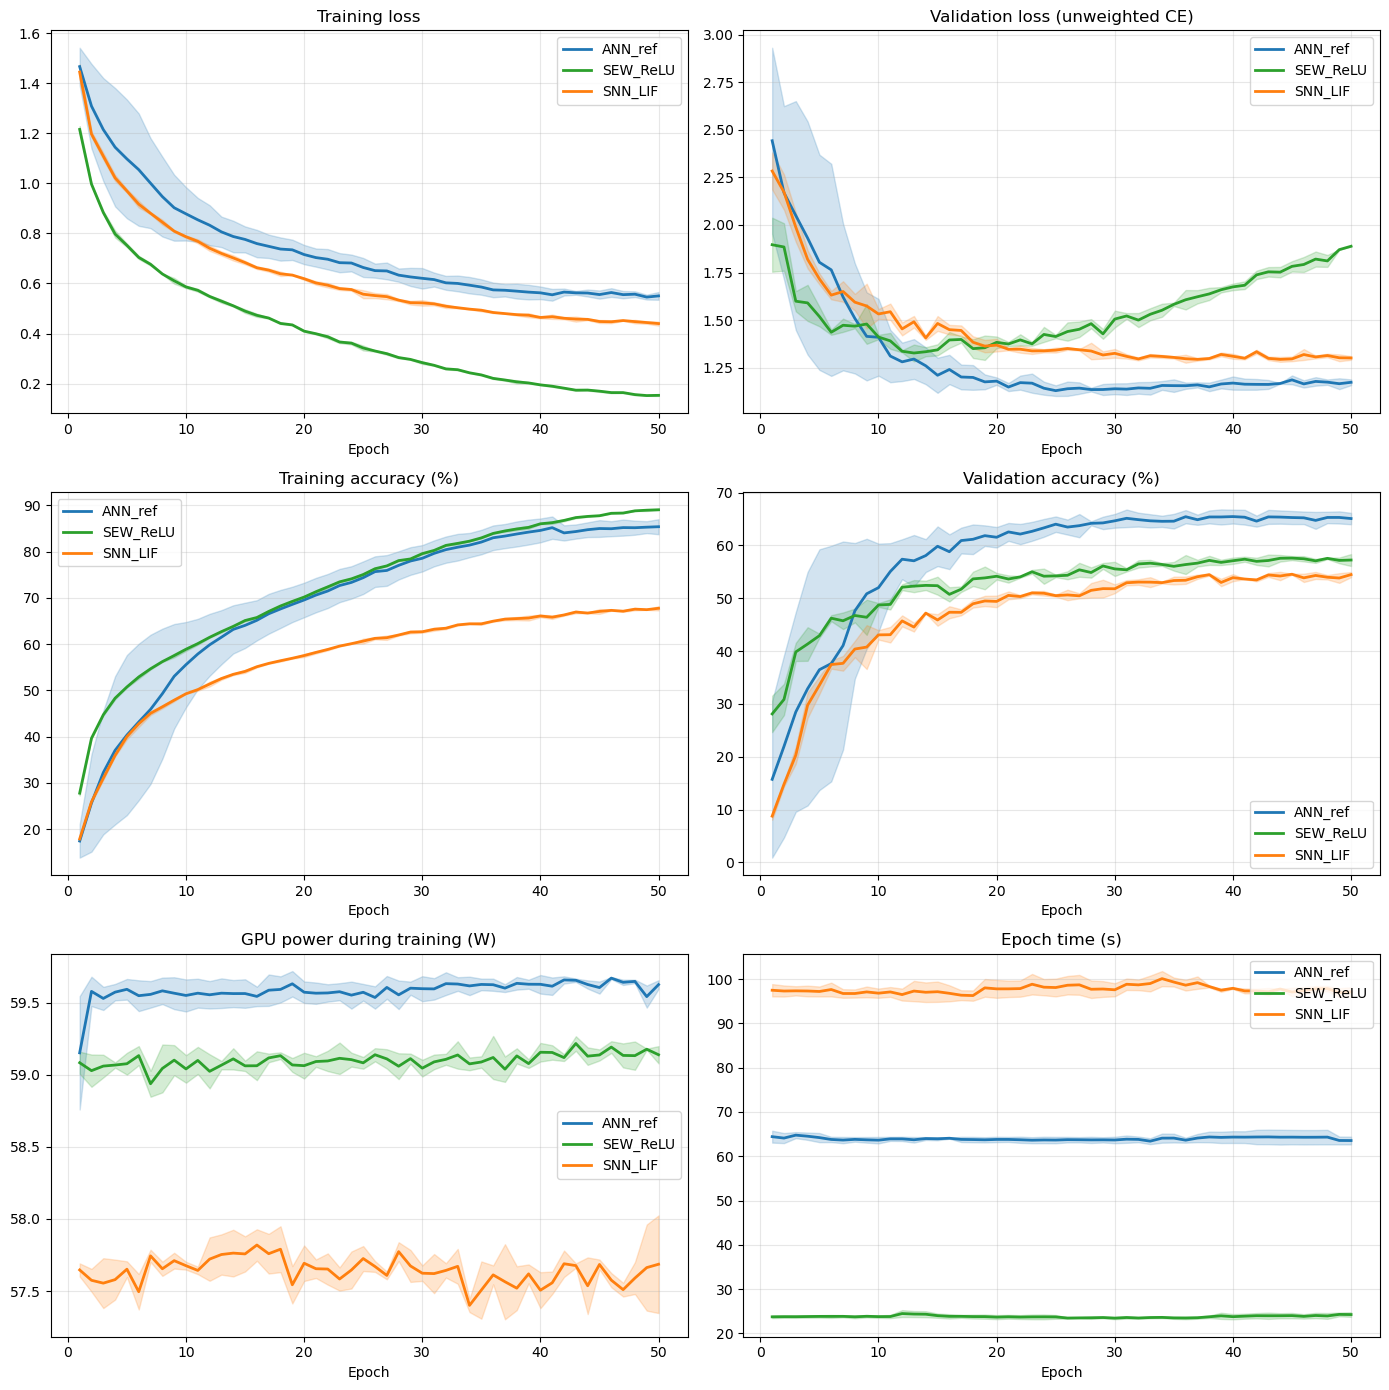

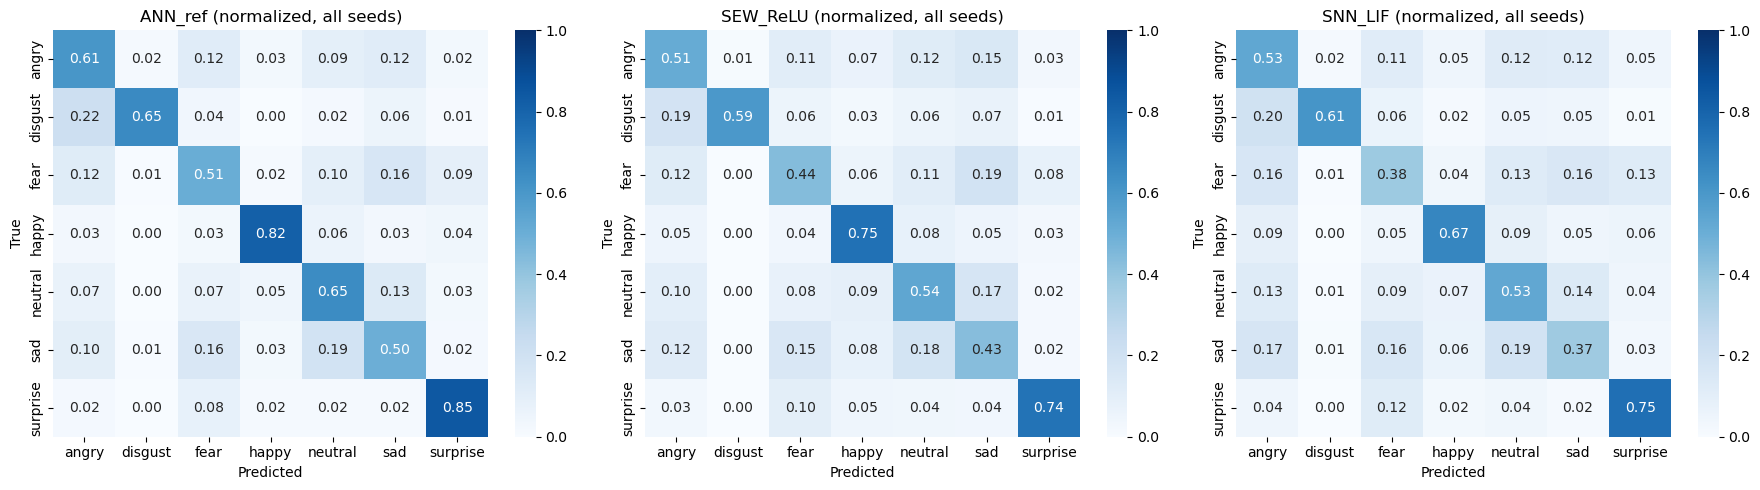

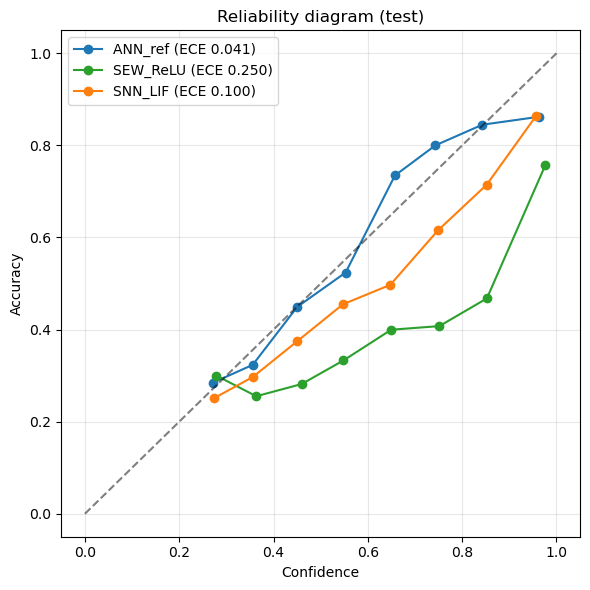

In [11]:
colors = {'ANN_ref': '#1f77b4', 'SEW_ReLU': '#2ca02c', 'SNN_LIF': '#ff7f0e'}

def curve_stats(model_key, field, scale=1.0):
    seqs = [r['history'][field] for r in runs if r['model'] == model_key]
    L = max(len(s) for s in seqs)
    M = np.full((len(seqs), L), np.nan)
    for i, s in enumerate(seqs):
        M[i, :len(s)] = np.array(s) * scale
    return np.arange(1, L + 1), np.nanmean(M, axis=0), np.nanstd(M, axis=0)

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
panels = [('train_loss', 'Training loss', 1), ('val_loss', 'Validation loss (unweighted CE)', 1),
          ('train_acc', 'Training accuracy (%)', 100), ('val_acc', 'Validation accuracy (%)', 100),
          ('train_power_w', 'GPU power during training (W)', 1), ('epoch_time_s', 'Epoch time (s)', 1)]
for ax, (field, title, scale) in zip(axes.ravel(), panels):
    for k in cfg.models_to_run:
        if any(r['model'] == k for r in runs):
            ep, m, s = curve_stats(k, field, scale)
            ax.plot(ep, m, color=colors.get(k), lw=2, label=k)
            ax.fill_between(ep, m - s, m + s, color=colors.get(k), alpha=0.2)
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{exp_dir}/figures/training_curves.png", dpi=300); plt.show()

# Confusion matrices summed over seeds, row-normalized
fig, axes = plt.subplots(1, len(cfg.models_to_run), figsize=(6 * len(cfg.models_to_run), 5))
axes = np.atleast_1d(axes)
for ax, k in zip(axes, cfg.models_to_run):
    cm = sum(np.array(r['test']['confusion']) for r in runs if r['model'] == k)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(f"{k} (normalized, all seeds)"); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); plt.savefig(f"{exp_dir}/figures/confusion_matrices.png", dpi=300); plt.show()

# Reliability diagram (seed 0)
fig, ax = plt.subplots(figsize=(6, 6))
edges = np.linspace(0, 1, 11)
for k, p in preds.items():
    conf = p['probs'].max(1); corr = (p['preds'] == p['labels']).astype(float)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 10:
            xs.append(conf[m].mean()); ys.append(corr[m].mean())
    ax.plot(xs, ys, marker='o', color=colors.get(k), label=f"{k} (ECE {expected_calibration_error(p['probs'], p['labels']):.3f})")
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_xlabel('Confidence'); ax.set_ylabel('Accuracy'); ax.set_title('Reliability diagram (test)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{exp_dir}/figures/reliability.png", dpi=300); plt.show()

## 11. Inference energy, latency and throughput (separate from training)

In [12]:
RUN_ENERGY = gpu_monitoring and torch.cuda.is_available()
energy_df = None

def load_model(model_key, seed):
    model = MODEL_SPECS[model_key]['builder']().to(device)
    ckpt  = torch.load(f"{exp_dir}/ckpt/{model_key}_seed{seed}.pth", map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval()

@torch.no_grad()
def preload_test_tensor(data, n=None):
    xs = [data['test_ds'][int(i)][0] for i in data['test_idx'][:n]]   # eval transform already applied
    return torch.stack(xs).to(device)

@torch.no_grad()
def measure_inference(model, X, batch_size, n_images, repeats, idle_w):
    model.eval(); X = X[:n_images]
    for i in range(0, min(len(X), batch_size * 10), batch_size):      # warm-up
        model(X[i:i + batch_size])
    torch.cuda.synchronize()
    out = []
    for _ in range(repeats):
        with GPUEnergyMeter() as m:
            for i in range(0, len(X), batch_size):
                model(X[i:i + batch_size])
        n = len(X); dyn = max(m.energy_J - idle_w * m.duration_s, 0.0)
        out.append(dict(energy_mJ_per_img=1000 * m.energy_J / n, dynamic_energy_mJ_per_img=1000 * dyn / n,
                        latency_ms_per_img=1000 * m.duration_s / n, throughput_img_s=n / m.duration_s,
                        avg_power_W=m.avg_power_W))
    return pd.DataFrame(out)

if RUN_ENERGY:
    X_test = preload_test_tensor(data)
    print("Measuring idle power (10 s)...")
    idle_w = measure_idle_power(10)
    print(f"Idle power: {idle_w:.1f} W | energy counter: {ENERGY_COUNTER_OK}")
    rows = []
    n_by_bs = {1: min(300, len(X_test)), 64: len(X_test)}
    repeats = 2 if cfg.quick_test else 5
    for key in cfg.models_to_run:
        model = load_model(key, cfg.seeds[0])
        for bs, n_img in n_by_bs.items():
            d = measure_inference(model, X_test, bs, n_img, repeats, idle_w)
            rows.append(dict(model=key, batch_size=bs, **d.mean().to_dict(),
                             **{f"{c}_std": d[c].std() for c in d.columns}))
            print(f"{key:<9} bs={bs:<3} {d['energy_mJ_per_img'].mean():8.2f} mJ/img | "
                  f"{d['latency_ms_per_img'].mean():7.2f} ms/img | {d['avg_power_W'].mean():5.1f} W")
        del model; torch.cuda.empty_cache()
    energy_df = pd.DataFrame(rows)
    display(energy_df.round(3))
    energy_df.to_csv(f"{exp_dir}/inference_energy.csv", index=False)
else:
    print("GPU monitoring unavailable: inference energy not measured.")

Measuring idle power (10 s)...
Idle power: 12.8 W | energy counter: True
ANN_ref   bs=1     124.41 mJ/img |    1.63 ms/img |  76.6 W
ANN_ref   bs=64     31.89 mJ/img |    0.51 ms/img |  62.3 W
[create_sew_resnet18] Architecture  : SEW-ResNet18 topology, ReLU control (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 1
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14
SEW_ReLU  bs=1     120.61 mJ/img |    1.68 ms/img |  71.7 W
SEW_ReLU  bs=64      5.45 mJ/img |    0.07 ms/img |  76.9 W
[create_sew_resnet18] Architecture  : SEW-ResNet18 (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 8
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14
SNN_LIF   bs=1     380.22 mJ/img |   10.75 ms/img |  35.4 W
SNN_LIF   bs=64     60.77 mJ/img |    1.00 ms/img |  60.5 W


,model,batch_size,energy_mJ_per_img,dynamic_energy_mJ_per_img,latency_ms_per_img,throughput_img_s,avg_power_W,energy_mJ_per_img_std,dynamic_energy_mJ_per_img_std,latency_ms_per_img_std,throughput_img_s_std,avg_power_W_std
0,ANN_ref,1,124.408,103.590,1.631,614.078,76.630,26.254,26.679,0.077,27.281,17.713
1,ANN_ref,64,31.894,25.361,0.512,1953.441,62.304,0.519,0.521,0.000,0.677,1.031
2,SEW_ReLU,1,120.609,99.135,1.683,594.352,71.699,14.552,14.599,0.006,2.086,8.816
3,SEW_ReLU,64,5.451,4.547,0.071,14109.555,76.920,0.719,0.720,0.000,15.723,10.217
4,SNN_LIF,1,380.221,243.028,10.750,93.046,35.374,15.571,15.224,0.173,1.467,1.436
5,SNN_LIF,64,60.769,47.950,1.004,995.628,60.503,0.570,0.568,0.001,0.887,0.559


## 12. Spike statistics and analytical operation counts (AFR, SynOps, MACs)

* **AFR / sparsity**: pooled and per layer, from forward hooks on every LIF layer (`SpikeStatsRecorder`).
* **Dense MACs**: multiply-accumulates of every Conv/Linear layer for one image over all time steps.
* **SynOps**: for each Conv layer fed by spikes, *measured input activity × dense MACs of that layer*. The stem convolution (analog input) and the classifier (average-pooled input) are counted as MACs.
* **Analytical energy** = MACs × E_MAC + SynOps × E_AC (Horowitz 2014 constants in `cfg`); it ignores memory traffic and neuron updates, so it is an estimate, not a measurement.

In [13]:
def dense_macs_per_image(mod, out):
    """Dense MACs of one Conv2d/Linear call for ONE image, summed over time steps."""
    multistep = getattr(mod, 'step_mode', None) == 'm'          # SpikingJelly multi-step layer: [T, B, ...]
    T = out.shape[0] if multistep else 1
    if isinstance(mod, nn.Conv2d):
        c_out, h_out, w_out = out.shape[-3:]
        c_in_g, kh, kw = mod.weight.shape[1:]
        return T * h_out * w_out * c_out * c_in_g * kh * kw
    return T * mod.in_features * mod.out_features


@torch.no_grad()
def analyze_ops(model, X, batch_size=64, n_images=1000, spiking=False):
    """Per-layer dense MACs and measured input activity for the first n_images of X."""
    model.eval(); X = X[:n_images]
    layers = OrderedDict((n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear)))
    stats = {n: dict(events=0.0, numel=0, macs=None) for n in layers}
    def make_hook(name):
        def hook(mod, inp, out):
            x = inp[0].detach(); s = stats[name]
            s['events'] += x.float().sum().item(); s['numel'] += x.numel()
            if s['macs'] is None:
                s['macs'] = dense_macs_per_image(mod, out)
        return hook
    handles = [m.register_forward_hook(make_hook(n)) for n, m in layers.items()]
    for i in range(0, len(X), batch_size):
        model(X[i:i + batch_size])
    for h in handles: h.remove()

    rows = []
    for n, s in stats.items():
        is_stem = n in ('conv1', 'backbone.conv1')
        is_linear = isinstance(layers[n], nn.Linear)
        ac_layer = spiking and not is_stem and not is_linear     # spike-driven synaptic layers
        fr = s['events'] / max(s['numel'], 1)
        rows.append(dict(layer=n, macs=s['macs'], input_activity=fr,
                         synops=fr * s['macs'] if ac_layer else 0.0,
                         mac_ops=0.0 if ac_layer else s['macs'], event_driven=ac_layer))
    df = pd.DataFrame(rows)
    return df, dict(macs_dense=float(df['macs'].sum()), synops=float(df['synops'].sum()),
                    mac_ops=float(df['mac_ops'].sum()))


def energy_estimate_uJ(ops, spiking):
    pj = (ops['mac_ops'] * cfg.e_mac_pj + ops['synops'] * cfg.e_ac_pj) if spiking else ops['macs_dense'] * cfg.e_mac_pj
    return pj * 1e-6


@torch.no_grad()
def analyze_spikes(model, loader):
    with SpikeStatsRecorder(model) as rec:
        n = 0
        for x, _ in loader:
            model(x.to(device)); n += x.size(0)
    return rec.summary(num_images=n)

In [14]:
X_ops = preload_test_tensor(data, n=500 if cfg.quick_test else 1000)
test_loader_eval = make_loaders(cfg.seeds[0], data, cfg)['test']

ops_rows, layer_tables = [], {}
for key in cfg.models_to_run:
    spiking = MODEL_SPECS[key]['kind'] == 'snn'
    model = load_model(key, cfg.seeds[0])
    df_l, ops = analyze_ops(model, X_ops, spiking=spiking)
    layer_tables[key] = df_l
    row = dict(model=key, dense_MACs=ops['macs_dense'], MAC_ops=ops['mac_ops'], SynOps=ops['synops'],
               est_energy_uJ=energy_estimate_uJ(ops, spiking))
    if spiking:
        sp = analyze_spikes(model, test_loader_eval)
        row.update(AFR=sp['afr'], sparsity=sp['sparsity'], spikes_per_image=sp['spikes_per_image'])
        layer_tables[key + '_afr'] = pd.DataFrame(
            [dict(layer=n, afr=v['afr'], neurons=v['neurons']) for n, v in sp['per_layer'].items()])
    ops_rows.append(row)
    del model; torch.cuda.empty_cache()

df_ops = pd.DataFrame(ops_rows)
ref = df_ops.loc[df_ops['model'] == 'ANN_ref', 'est_energy_uJ']
if len(ref):
    df_ops['energy_ratio_vs_ANN_ref'] = df_ops['est_energy_uJ'] / float(ref.iloc[0])
ctrl = df_ops.loc[df_ops['model'] == 'SEW_ReLU', 'est_energy_uJ']
if len(ctrl):
    df_ops['energy_ratio_vs_SEW_ReLU'] = df_ops['est_energy_uJ'] / float(ctrl.iloc[0])
pd.set_option('display.float_format', lambda v: f"{v:.4g}")
display(df_ops)
df_ops.to_csv(f"{exp_dir}/ops_and_spikes.csv", index=False)
for k, t in layer_tables.items():
    t.to_csv(f"{exp_dir}/layers_{k}.csv", index=False)
if 'SNN_LIF_afr' in layer_tables:
    display(layer_tables['SNN_LIF_afr'])

[create_sew_resnet18] Architecture  : SEW-ResNet18 topology, ReLU control (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 1
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14
[create_sew_resnet18] Architecture  : SEW-ResNet18 (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 8
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14


,model,dense_MACs,MAC_ops,SynOps,est_energy_uJ,AFR,sparsity,spikes_per_image,energy_ratio_vs_ANN_ref,energy_ratio_vs_SEW_ReLU
0,ANN_ref,1.101e+09,1.101e+09,0,5065,NaN,NaN,NaN,1,11.67
1,SEW_ReLU,9.435e+07,9.435e+07,0,434,NaN,NaN,NaN,0.08568,1
2,SNN_LIF,7.548e+08,1.448e+07,8.111e+07,139.6,0.05918,0.9408,5.612e+04,0.02756,0.3217


,layer,afr,neurons
0,sn1,0.06424,2116878336
1,layer1.0.sn1,0.06205,529219584
2,layer1.0.sn2,0.05379,529219584
3,layer1.1.sn1,0.06422,529219584
4,layer1.1.sn2,0.05453,529219584
5,layer2.0.sn1,0.06971,264609792
6,layer2.0.sn2,0.06715,264609792
7,layer2.0.downsample_sn,0.06249,264609792
8,layer2.1.sn1,0.05473,264609792
9,layer2.1.sn2,0.04539,264609792


## 13. Optional: ablation on the number of time steps T (one seed per T)

In [15]:
RUN_T_ABLATION = False          # set to True to train one SNN per T (long)
T_LIST = [1, 2, 4, 8]
t_rows = []
if RUN_T_ABLATION:
    for T in T_LIST:
        key = f"SNN_T{T}"
        MODEL_SPECS[key] = dict(MODEL_SPECS['SNN_LIF'], description=f"SNN, T={T}",
                                builder=(lambda T=T: create_sew_resnet18(cfg.num_classes, T, activation='lif')))
        if not os.path.exists(f"{exp_dir}/runs/{key}_seed{cfg.seeds[0]}.json"):
            train_one(key, cfg.seeds[0], cfg, data, exp_dir)
        with open(f"{exp_dir}/runs/{key}_seed{cfg.seeds[0]}.json") as f:
            r = json.load(f)
        model = load_model(key, cfg.seeds[0])
        _, ops = analyze_ops(model, X_ops, spiking=True)
        sp = analyze_spikes(model, test_loader_eval)
        t_rows.append(dict(T=T, test_acc=r['test']['acc'], AFR=sp['afr'], spikes_per_image=sp['spikes_per_image'],
                           SynOps=ops['synops'], est_energy_uJ=energy_estimate_uJ(ops, True)))
        del model; torch.cuda.empty_cache()
    df_T = pd.DataFrame(t_rows); display(df_T); df_T.to_csv(f"{exp_dir}/ablation_T.csv", index=False)
else:
    print("T ablation skipped (RUN_T_ABLATION = False).")

T ablation skipped (RUN_T_ABLATION = False).


## 14. Export

In [16]:
summary_flat = summary_table.copy()
summary_flat.columns = ['_'.join(map(str, c)) for c in summary_flat.columns]
export = dict(
    environment=ENV, config=to_jsonable(vars(cfg)),
    split=dict(train=len(data['tr_idx']), val=len(data['va_idx']), test=len(data['test_idx']),
               classes=data['classes'], train_counts=data['counts'].tolist()),
    models={k: {kk: vv for kk, vv in v.items() if kk != 'builder'} for k, v in MODEL_SPECS.items()
            if k in cfg.models_to_run},
    summary_over_seeds=json.loads(summary_flat.to_json(orient='index')),
    ops_and_spikes=json.loads(df_ops.to_json(orient='records')),
    inference_energy=(json.loads(energy_df.to_json(orient='records')) if energy_df is not None else None),
)
with open(f"{exp_dir}/summary.json", 'w') as f:
    json.dump(to_jsonable(export), f, indent=2)
print(f"Saved to {exp_dir}/ : summary.json, runs/, ckpt/, figures/, *.csv")

Saved to sew_resnet18_results_v2/20261103_212511/ : summary.json, runs/, ckpt/, figures/, *.csv


## 15. Single-image inference (all models)

[create_sew_resnet18] Architecture  : SEW-ResNet18 topology, ReLU control (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 1
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14
[create_sew_resnet18] Architecture  : SEW-ResNet18 (SpikingJelly)
[create_sew_resnet18] Parameters    : 11,173,831
[create_sew_resnet18] Timesteps     : 8
[create_sew_resnet18] Input min-max : True
[create_sew_resnet18] SpikingJelly  : 0.0.0.0.14


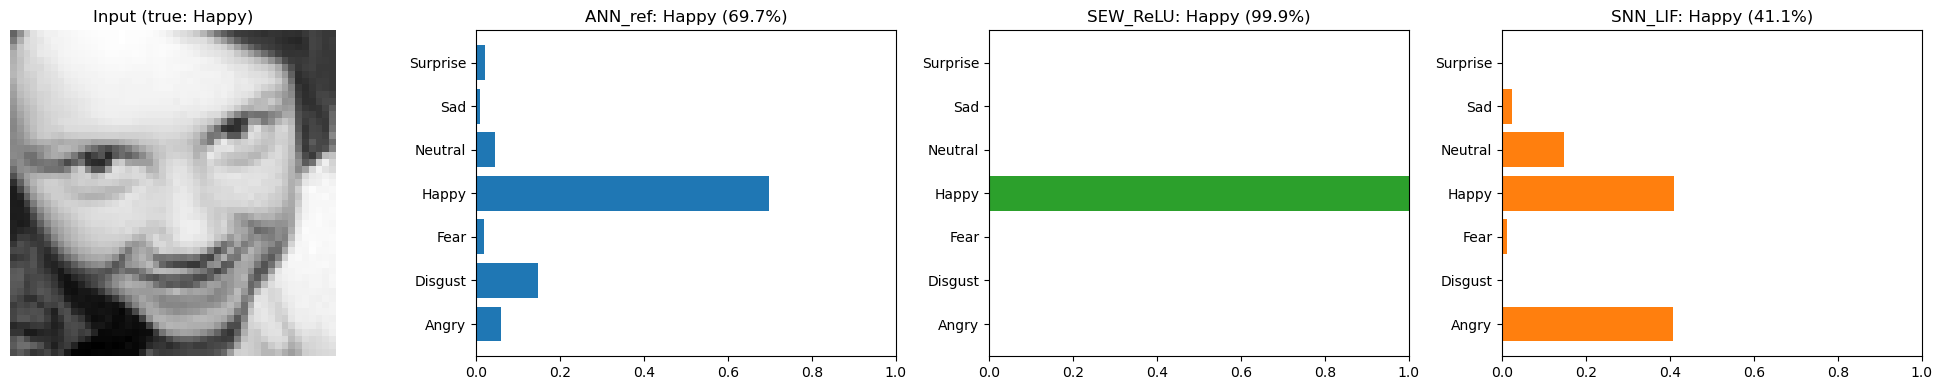

In [17]:
from PIL import Image
CLASS_NAMES = [c.capitalize() for c in data['classes']]
_model_cache = {}

def _get(key, seed):
    if (key, seed) not in _model_cache:
        _model_cache[(key, seed)] = load_model(key, seed)
    return _model_cache[(key, seed)]

@torch.no_grad()
def test_image(path, true_label=None, seed=None, save_path=None):
    """Predict one image with every model; shows the input and the class probabilities."""
    seed = cfg.seeds[0] if seed is None else seed
    img = Image.open(path)
    x = transform_eval(img).unsqueeze(0).to(device)
    fig, axes = plt.subplots(1, len(cfg.models_to_run) + 1, figsize=(5 * (len(cfg.models_to_run) + 1), 4))
    axes[0].imshow((x.squeeze().cpu().numpy() * 0.266 + 0.499).clip(0, 1), cmap='gray')
    axes[0].set_title(f"Input (true: {true_label})" if true_label else "Input"); axes[0].axis('off')
    for ax, key in zip(axes[1:], cfg.models_to_run):
        probs = torch.softmax(_get(key, seed)(x), dim=1).squeeze().cpu().numpy()
        ax.barh(CLASS_NAMES, probs, color=colors.get(key, 'gray'))
        ax.set_xlim(0, 1); ax.set_title(f"{key}: {CLASS_NAMES[probs.argmax()]} ({probs.max()*100:.1f}%)")
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=200)
    plt.show()

# Example (edit the path):
test_image(f"{cfg.dataset_path}/test/happy/PrivateTest_2309763.jpg", true_label="Happy")

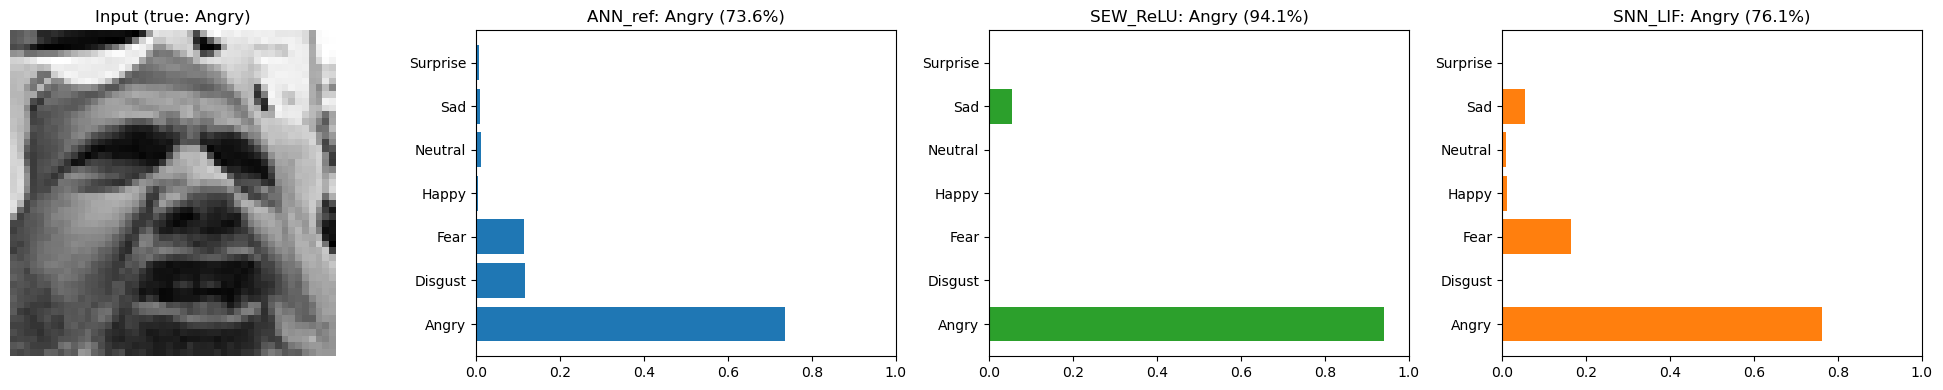

In [18]:
test_image(f"{cfg.dataset_path}/test/angry/PrivateTest_731447.jpg", true_label="Angry")

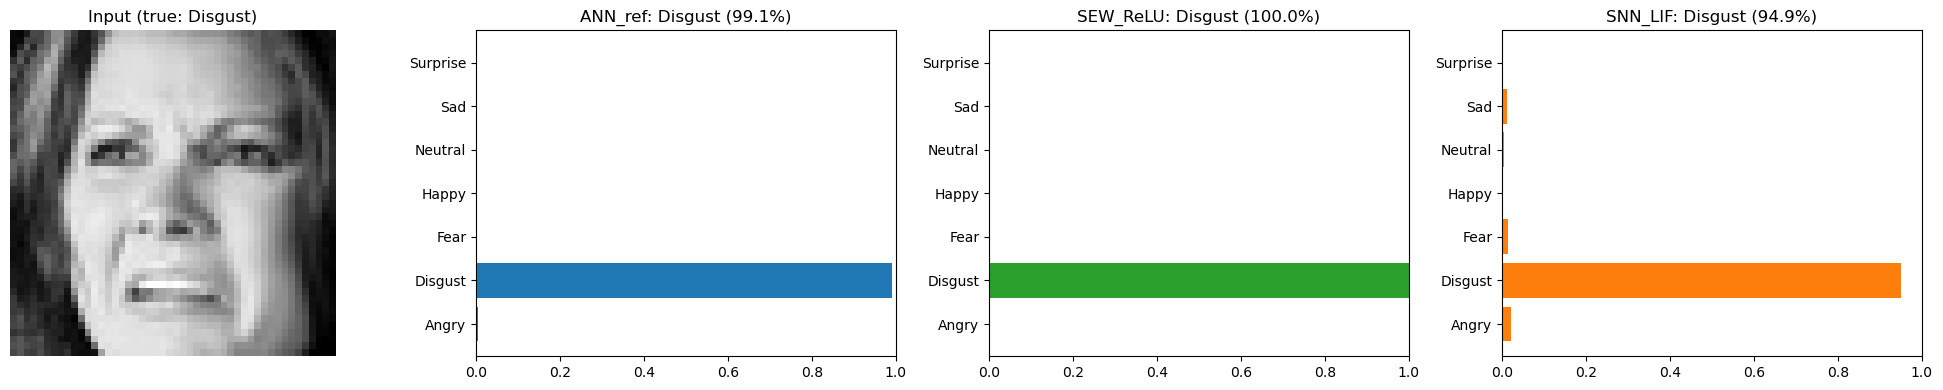

In [19]:
test_image(f"{cfg.dataset_path}/test/disgust/PrivateTest_4783181.jpg", true_label="Disgust")

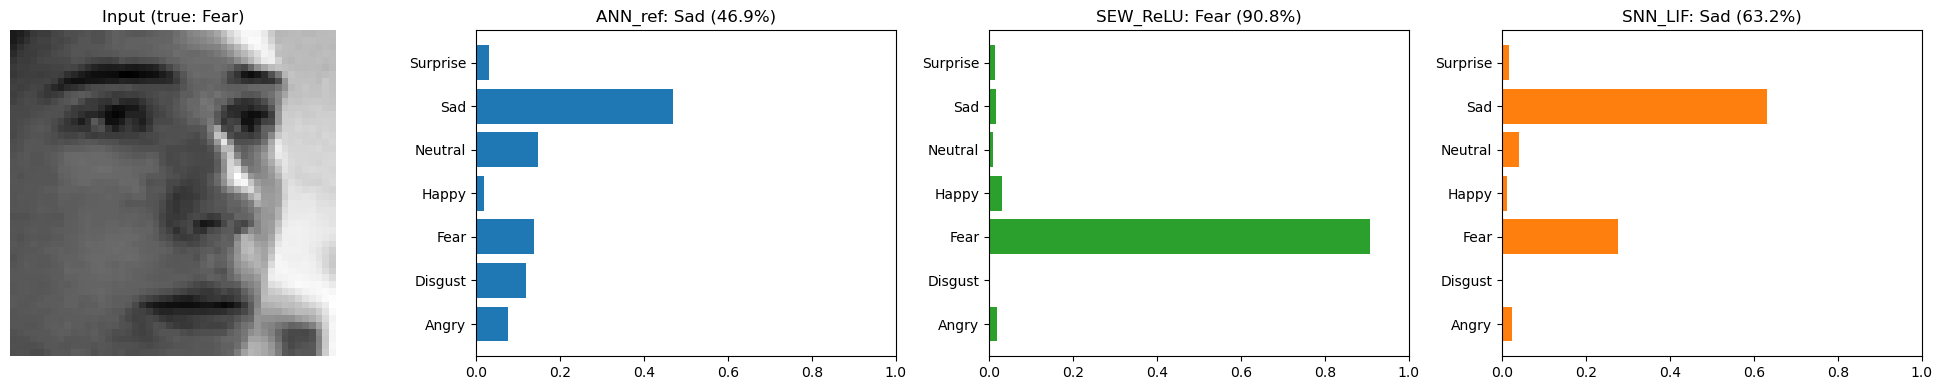

In [20]:
test_image(f"{cfg.dataset_path}/test/fear/PrivateTest_2178829.jpg", true_label="Fear")

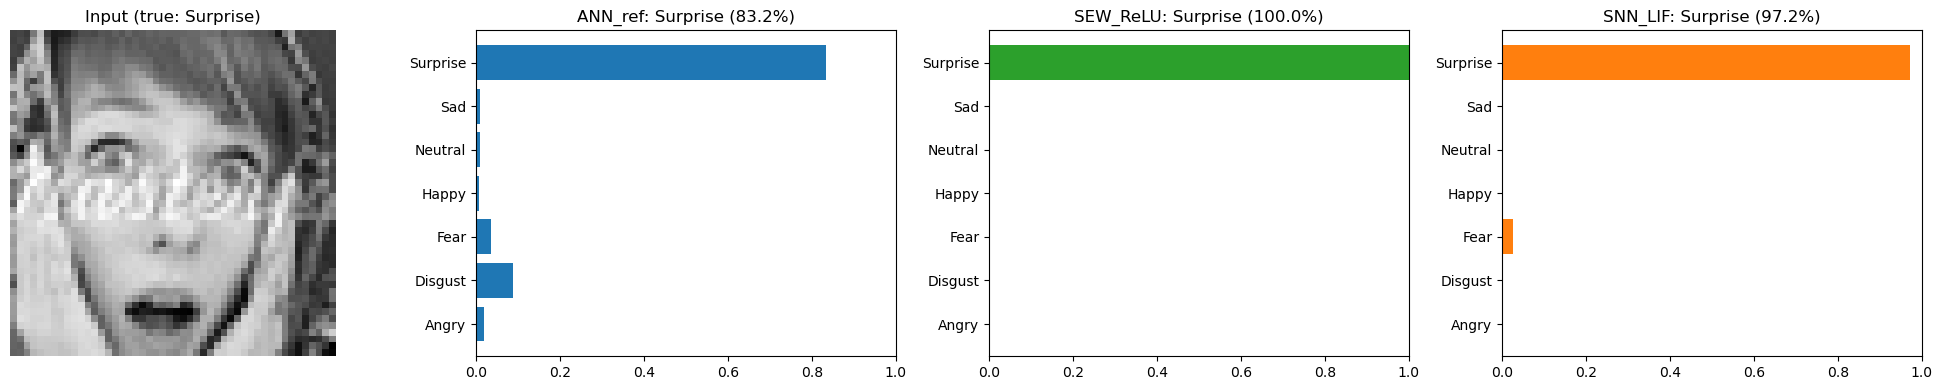

In [21]:
test_image(f"{cfg.dataset_path}/test/surprise/PrivateTest_139065.jpg", true_label="Surprise")